# Football Player Match Rating — EDA & CatBoost Regression

**Dataset:** `football_player_rating_dataset.csv`  
**Target:** `player_rating` (`float64`)  
**Unit of observation:** one player's performance in one match  
**Problem type:** supervised regression

## Objective
1. Audit all 63 columns before making modeling conclusions.
2. Treat missing values using football meaning, not a generic imputation rule.
3. Check duplicates at full-row and player-match level.
4. Review outliers but retain legitimate extreme football performances.
5. Remove identifiers/redundant variables that are not appropriate for the prediction stage.
6. Use a time-aware train/validation/test split.
7. Fit and evaluate a CatBoost regression model.
8. Interpret feature importance and residuals in football terms.

> **Important modeling interpretation:** this notebook estimates the rating from statistics produced in the same match. It is **not** a pre-match forecast, because variables such as goals, assists, tackles and passes are only known after/during the match.

## 0. Analysis plan

The analysis follows five football feature groups:

1. **Identifiers**
2. **Contextual**
3. **Match Features**
4. **Attacking Features** — including dribbling, passing/progression, crossing and long passing
5. **Defensive Features** — including defensive actions, duels and fouls

`player_rating` is kept separate as the target.

The notebook deliberately performs the missing-value and data-quality audit **before** target/model conclusions.

In [1]:

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 180)


In [2]:
DATA_PATH=Path("football_player_rating_dataset.csv")

df_raw = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head())

Loaded: football_player_rating_dataset.csv
Shape: (173587, 63)


,match_id,match_date,league_id,league_name,country_code,parent_league_name,parent_league_season,home_team_id,home_team_name,away_team_id,away_team_name,home_score,away_score,is_home_team,team_goals,opponent_goals,goal_difference,team_result,player_id,player_name,team_id,team_name,is_goalkeeper,player_rating,minutes_played,goals,assists,shots_on_target,blocked_shots,expected_assists,xg_plus_xa,chances_created,touches,touches_opp_box,successful_dribbles,dribble_attempts,dribble_success_rate,accurate_passes,total_passes,pass_accuracy,passes_final_third,accurate_crosses,cross_attempts,cross_success_rate,accurate_long_balls,long_ball_attempts,long_ball_success_rate,tackles_won,interceptions,clearances,defensive_actions,recoveries,dribbled_past,duels_won,duels_lost,ground_duels_won,ground_duel_attempts,ground_duel_success_rate,aerial_duels_won,aerial_duel_attempts,aerial_duel_success_rate,fouls_committed,was_fouled
0,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,452269,Lucas Evangelista,109705,Bragantino,0,7.16,89.0,0.0,0.0,0.0,1.0,NaN,NaN,2.0,64,1.0,1.0,1.0,100.0,35,47,74.500000,6.0,2.0,10.0,20.0,0.0,3.0,0.000000,2,0,0,2,2,0.0,4.0,NaN,4.0,4.0,100.000000,0.0,0.0,NaN,0,1.0
1,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,612191,André Cardoso,109705,Bragantino,0,6.41,11.0,0.0,0.0,NaN,0.0,NaN,NaN,0.0,21,0.0,NaN,NaN,NaN,15,17,88.199997,2.0,NaN,NaN,NaN,4.0,5.0,80.000000,3,0,0,3,1,0.0,3.0,2.0,3.0,5.0,60.000000,0.0,0.0,NaN,1,NaN
2,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,768389,Cleiton Schwengber,109705,Bragantino,1,6.79,90.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46,NaN,NaN,NaN,NaN,28,34,82.400002,4.0,NaN,NaN,NaN,4.0,9.0,44.400002,0,0,0,0,12,NaN,1.0,NaN,NaN,NaN,NaN,1.0,1.0,100.000000,0,NaN
3,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,844510,Juninho Capixaba,109705,Bragantino,0,7.91,90.0,0.0,1.0,NaN,0.0,NaN,NaN,2.0,91,1.0,2.0,2.0,100.0,56,64,87.500000,13.0,0.0,5.0,0.0,4.0,5.0,80.000000,0,2,3,5,6,2.0,4.0,5.0,3.0,7.0,42.900002,1.0,2.0,50.000000,1,1.0
4,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,Novorizontino,1,2,1,1.0,2.0,-1.0,loss,920420,Eduardo Santos,109705,Bragantino,0,7.47,90.0,0.0,0.0,0.0,1.0,NaN,NaN,0.0,80,1.0,NaN,NaN,NaN,62,65,95.400002,7.0,NaN,NaN,NaN,2.0,3.0,66.699997,3,1,5,9,7,1.0,4.0,3.0,3.0,4.0,75.000000,1.0,3.0,33.299999,0,NaN


## 1. Football-specific column grouping

The grouping below is intentionally broad. Dribbling, passing, progression, crossing and long passing belong to **Attacking Features**. Defensive actions, duels and fouls belong to **Defensive Features**.

In [3]:
TARGET = "player_rating"

IDENTIFIERS = [
    "match_id", "league_id", "league_name",
    "home_team_id", "home_team_name",
    "away_team_id", "away_team_name",
    "player_id", "player_name",
    "team_id", "team_name"
]

CONTEXTUAL = [
    "match_date", "country_code", "parent_league_name", "parent_league_season"
     
]

MATCH_FEATURES = [
    "home_score", "away_score","minutes_played", "is_home_team", "team_goals", "opponent_goals", "goal_difference", "team_result", "is_goalkeeper"
]

ATTACKING = [
    "goals", "assists", "shots_on_target", "blocked_shots",
    "expected_assists", "xg_plus_xa", "chances_created",
    "touches", "touches_opp_box",
    "successful_dribbles", "dribble_attempts", "dribble_success_rate",
    "accurate_passes", "total_passes", "pass_accuracy", "passes_final_third",
    "accurate_crosses", "cross_attempts", "cross_success_rate",
    "accurate_long_balls", "long_ball_attempts", "long_ball_success_rate"
]

DEFENSIVE = [
    "tackles_won", "interceptions", "clearances", "defensive_actions",
    "recoveries", "dribbled_past",
    "duels_won", "duels_lost",
    "ground_duels_won", "ground_duel_attempts", "ground_duel_success_rate",
    "aerial_duels_won", "aerial_duel_attempts", "aerial_duel_success_rate",
    "fouls_committed", "was_fouled"
]

GROUPS = {
    "Identifiers": IDENTIFIERS,
    "Contextual": CONTEXTUAL,
    "Match Features": MATCH_FEATURES,
    "Attacking Features": ATTACKING,
    "Defensive Features": DEFENSIVE
}

all_grouped = sum(GROUPS.values(), []) + [TARGET]
assert len(all_grouped) == len(set(all_grouped)), "A column appears in more than one group."
assert set(all_grouped) == set(df_raw.columns), (
    f"Grouping mismatch. Missing={set(df_raw.columns)-set(all_grouped)}, "
    f"Extra={set(all_grouped)-set(df_raw.columns)}"
)

group_table = pd.DataFrame(
    [(group, col) for group, cols in GROUPS.items() for col in cols] + [("Target", TARGET)],
    columns=["football_group", "column"]
)
display(group_table)
print("All", len(df_raw.columns), "columns are assigned exactly once.")

,football_group,column
0,Identifiers,match_id
1,Identifiers,league_id
2,Identifiers,league_name
3,Identifiers,home_team_id
4,Identifiers,home_team_name
5,Identifiers,away_team_id
6,Identifiers,away_team_name
7,Identifiers,player_id
8,Identifiers,player_name
9,Identifiers,team_id


All 63 columns are assigned exactly once.


# 2. Full data-quality audit — all 63 columns

No modeling conclusion is made before this audit.

For every column we inspect:
- type
- football group
- missing count and %
- unique values
- zero count
- basic numeric range / central tendency
- blank strings for text fields
- constant / near-constant behavior

In [4]:
df = df_raw.copy()
df["match_date"] = pd.to_datetime(df["match_date"], errors="coerce")

group_lookup = {col: group for group, cols in GROUPS.items() for col in cols}
group_lookup[TARGET] = "Target"

rows = []
for col in df.columns:
    s = df[col]
    is_num = pd.api.types.is_numeric_dtype(s)
    value_counts = s.value_counts(dropna=False, normalize=True)
    top_freq_pct = float(value_counts.iloc[0] * 100) if len(value_counts) else np.nan
    blank_count = int(s.astype(str).str.strip().eq("").sum()) if s.dtype == "object" else 0

    rows.append({
        "column": col,
        "football_group": group_lookup[col],
        "dtype": str(s.dtype),
        "missing_n": int(s.isna().sum()),
        "missing_pct": round(float(s.isna().mean() * 100), 3),
        "unique_n": int(s.nunique(dropna=True)),
        "zero_n": int((s == 0).sum()) if is_num else np.nan,
        "min": s.min() if is_num else np.nan,
        "q01": s.quantile(0.01) if is_num else np.nan,
        "median": s.median() if is_num else np.nan,
        "mean": s.mean() if is_num else np.nan,
        "q99": s.quantile(0.99) if is_num else np.nan,
        "max": s.max() if is_num else np.nan,
        "blank_strings": blank_count,
        "top_value_pct": round(top_freq_pct, 3),
        "constant": bool(s.nunique(dropna=False) <= 1),
        "near_constant_99pct": bool(top_freq_pct >= 99 and s.nunique(dropna=False) > 1)
    })
audit = pd.DataFrame(rows)
display(audit)
print("Audited columns:", len(audit))

,column,football_group,dtype,missing_n,missing_pct,unique_n,zero_n,min,q01,median,mean,q99,max,blank_strings,top_value_pct,constant,near_constant_99pct
0,match_id,Identifiers,int64,0,0.000,6818,0.0,4196553.00,4493702.00,4692715.00,7.083235e+06,4790908.00,1.000001e+09,0,0.020,False,False
1,match_date,Contextual,datetime64[ns],0,0.000,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3.327,False,False
2,league_id,Identifiers,int64,0,0.000,201,0.0,47.00,47.00,893033.00,7.463272e+05,10000002.00,1.000000e+07,0,2.405,False,False
3,league_name,Identifiers,object,0,0.000,188,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3.401,False,False
4,country_code,Contextual,object,0,0.000,46,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,10.772,False,False
5,parent_league_name,Contextual,object,0,0.000,188,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3.401,False,False
6,parent_league_season,Contextual,int64,0,0.000,1,0.0,2025.00,2025.00,2025.00,2.025000e+03,2025.00,2.025000e+03,0,100.000,True,False
7,home_team_id,Identifiers,int64,0,0.000,1286,0.0,1567.00,1843.00,9863.00,2.231961e+05,1729987.00,1.730349e+06,0,0.218,False,False
8,home_team_name,Identifiers,object,0,0.000,1231,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.304,False,False
9,away_team_id,Identifiers,int64,0,0.000,1288,0.0,1567.00,1842.00,9860.00,2.254658e+05,1729988.00,1.730349e+06,0,0.202,False,False


Audited columns: 63


In [5]:
print("Dataset shape:", df.shape)
print("Matches:", df["match_id"].nunique())
print("Players (IDs):", df["player_id"].nunique())
print("Teams (IDs):", df["team_id"].nunique())
print("League IDs:", df["league_id"].nunique())
print("League names:", df["league_name"].nunique())
print("Constant columns:", audit.loc[audit["constant"], "column"].tolist())
print("Near-constant columns (>=99% same value):", audit.loc[audit["near_constant_99pct"], "column"].tolist())

Dataset shape: (173587, 63)
Matches: 6818
Players (IDs): 27974
Teams (IDs): 1348
League IDs: 201
League names: 188
Constant columns: ['parent_league_season']
Near-constant columns (>=99% same value): []


## 2.1 Duplicate checks

The key football integrity check is whether the same player appears more than once for the same match.

In [6]:
duplicate_summary = pd.DataFrame({
    "check": [
        "Full-row duplicates",
        "match_id + player_id duplicates",
        "match_id + player_id + team_id duplicates"
    ],
    "duplicate_rows": [
        int(df.duplicated().sum()),
        int(df.duplicated(["match_id", "player_id"]).sum()),
        int(df.duplicated(["match_id", "player_id", "team_id"]).sum())
    ]
})
display(duplicate_summary)

,check,duplicate_rows
0,Full-row duplicates,0
1,match_id + player_id duplicates,0
2,match_id + player_id + team_id duplicates,0


## 3. Meaningless / inconsistent match-context entries

`team_result` contains the literal category `"unknown"`, so it must be investigated rather than silently treated as a legitimate result.

We also validate whether each player's `team_id` matches either the match `home_team_id` or `away_team_id`.

In [7]:
team_link_valid = df["team_id"].eq(df["home_team_id"]) | df["team_id"].eq(df["away_team_id"])
unknown_result = df["team_result"].eq("unknown")
missing_match_triplet = (
    df["team_goals"].isna()
    & df["opponent_goals"].isna()
    & df["goal_difference"].isna()
)

context_issue_summary = pd.Series({
    "team_id_not_home_or_away": int((~team_link_valid).sum()),
    "team_result_unknown": int(unknown_result.sum()),
    "team_goals/opponent_goals/goal_difference_all_missing": int(missing_match_triplet.sum()),
    "same_rows_for_all_three_patterns": bool((~team_link_valid).equals(unknown_result) and unknown_result.equals(missing_match_triplet))
})
display(context_issue_summary.to_frame("result"))

# Show a small sample for manual review.
issue_cols = [
    "match_id", "match_date", "home_team_id", "home_team_name",
    "away_team_id", "away_team_name", "team_id", "team_name",
    "is_home_team", "team_goals", "opponent_goals", "goal_difference", "team_result"
]
display(df.loc[~team_link_valid, issue_cols].head(20))

,result
team_id_not_home_or_away,253
team_result_unknown,253
team_goals/opponent_goals/goal_difference_all_missing,253
same_rows_for_all_three_patterns,True


,match_id,match_date,home_team_id,home_team_name,away_team_id,away_team_name,team_id,team_name,is_home_team,team_goals,opponent_goals,goal_difference,team_result
4543,4548637,2025-02-02,189475,Sudtirol,6500,AC Reggiana 1919,959006,Reggiana,0,NaN,NaN,NaN,unknown
4544,4548637,2025-02-02,189475,Sudtirol,6500,AC Reggiana 1919,959006,Reggiana,0,NaN,NaN,NaN,unknown
4545,4548637,2025-02-02,189475,Sudtirol,6500,AC Reggiana 1919,959006,Reggiana,0,NaN,NaN,NaN,unknown
4546,4548637,2025-02-02,189475,Sudtirol,6500,AC Reggiana 1919,959006,Reggiana,0,NaN,NaN,NaN,unknown
4547,4548637,2025-02-02,189475,Sudtirol,6500,AC Reggiana 1919,959006,Reggiana,0,NaN,NaN,NaN,unknown
4548,4548637,2025-02-02,189475,Sudtirol,6500,AC Reggiana 1919,959006,Reggiana,0,NaN,NaN,NaN,unknown
4549,4548637,2025-02-02,189475,Sudtirol,6500,AC Reggiana 1919,959006,Reggiana,0,NaN,NaN,NaN,unknown
4550,4548637,2025-02-02,189475,Sudtirol,6500,AC Reggiana 1919,959006,Reggiana,0,NaN,NaN,NaN,unknown
4551,4548637,2025-02-02,189475,Sudtirol,6500,AC Reggiana 1919,959006,Reggiana,0,NaN,NaN,NaN,unknown
4552,4548637,2025-02-02,189475,Sudtirol,6500,AC Reggiana 1919,959006,Reggiana,0,NaN,NaN,NaN,unknown


# 4. Missing-value analysis and decisions

We first describe the missingness, then decide whether to preserve, recode a meaningless placeholder, or exclude a problematic row from the model.

,column,football_group,missing_n,missing_pct,dtype,unique_n,zero_n
0,expected_assists,Attacking Features,109655,63.170,float64,127,0.0
1,xg_plus_xa,Attacking Features,103067,59.375,float64,227,0.0
2,accurate_crosses,Attacking Features,98270,56.611,float64,12,42537.0
3,cross_attempts,Attacking Features,98270,56.611,float64,25,0.0
4,cross_success_rate,Attacking Features,98270,56.611,float64,87,42537.0
5,shots_on_target,Attacking Features,92611,53.351,float64,11,43677.0
6,was_fouled,Defensive Features,91436,52.674,float64,10,0.0
7,dribble_attempts,Attacking Features,90974,52.408,float64,16,0.0
8,dribble_success_rate,Attacking Features,90974,52.408,float64,52,31041.0
9,successful_dribbles,Attacking Features,90974,52.408,float64,14,31041.0


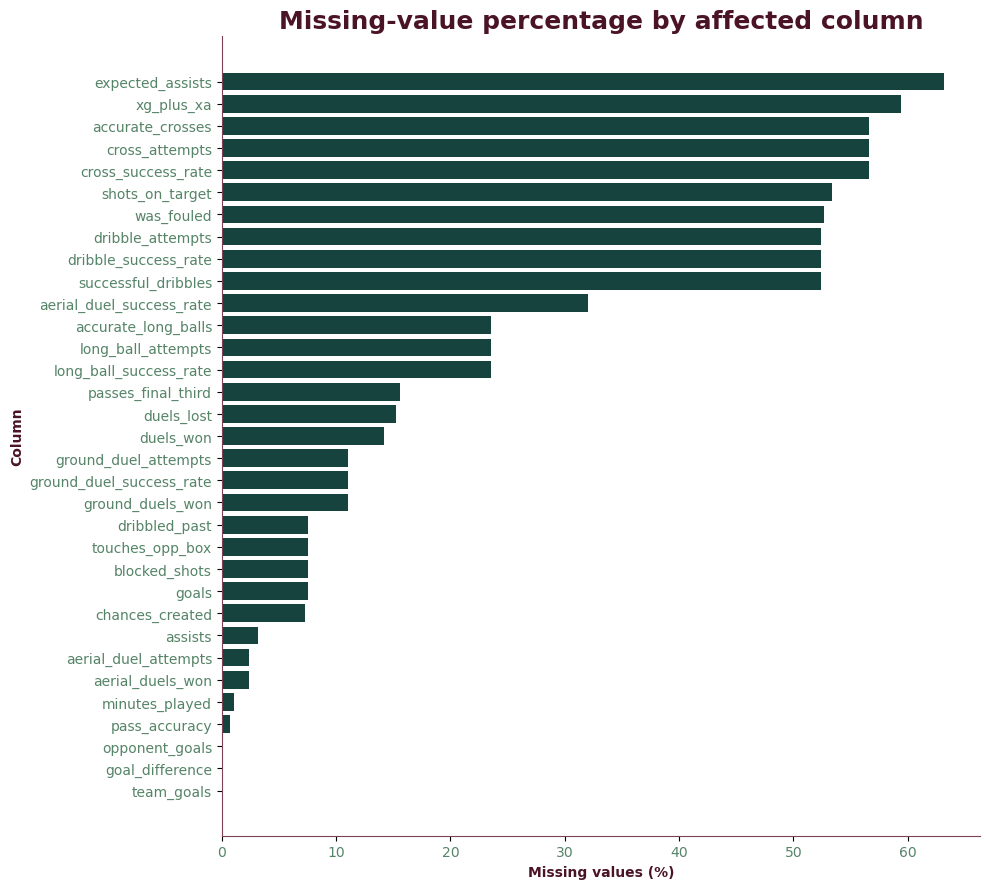

In [8]:
missing_table = (
    audit.loc[audit["missing_n"] > 0,
              ["column", "football_group", "missing_n", "missing_pct", "dtype", "unique_n", "zero_n"]]
    .sort_values(["missing_pct", "column"], ascending=[False, True])
    .reset_index(drop=True)
)
display(missing_table)

plt.figure(figsize=(10, 9))
plot_df = missing_table.sort_values("missing_pct")
plt.barh(plot_df["column"], plot_df["missing_pct"],color="#17433F")
plt.xlabel("Missing values (%)",color="#4B1426",weight="bold")
plt.ylabel("Column",color="#4B1426",weight="bold")
plt.title("Missing-value percentage by affected column",color="#4B1426",fontsize=18,weight="bold")
plt.xticks(color="#558467")
plt.yticks(color="#558467")
ax=plt.gca()
ax.spines[["top","right"]].set_visible(False)
ax.spines[["bottom","left"]].set_color("#7E4256")
plt.tight_layout()
plt.show()


## 4.1 Goalkeeper vs outfield missingness

This diagnostic does **not** assume only goalkeepers can have missing values. It checks whether role explains part of the missingness pattern.

In [10]:
affected = missing_table["column"].tolist()
gk_missing_rows = []

for col in affected:
    for gk_value, label in [(0, "Outfield"), (1, "Goalkeeper")]:
        sub = df.loc[df["is_goalkeeper"].eq(gk_value), col]
        gk_missing_rows.append({
            "column": col,
            "player_type": label,
            "missing_n": int(sub.isna().sum()),
            "missing_pct": round(float(sub.isna().mean() * 100), 3)
        })

gk_missing = pd.DataFrame(gk_missing_rows)
gk_missing_pivot = gk_missing.pivot(
    index="column", columns="player_type", values="missing_pct"
).reset_index()

display(gk_missing_pivot.sort_values("Goalkeeper", ascending=False))

player_type,column,Goalkeeper,Outfield
0,accurate_crosses,100.000,53.057
30,touches_opp_box,100.000,0.000
8,cross_attempts,100.000,53.057
9,cross_success_rate,100.000,53.057
12,dribbled_past,100.000,0.000
6,blocked_shots,99.916,0.000
17,goals,99.893,0.000
27,shots_on_target,99.346,49.584
28,successful_dribbles,97.839,48.687
10,dribble_attempts,97.839,48.687


## 4.2 Missingness by competition/provider context

For high-missing advanced metrics, whole competitions may have incomplete coverage. That is different from a true player value of zero.

In [11]:
HIGH_MISSING_THRESHOLD = 20
high_missing_cols = missing_table.loc[
    missing_table["missing_pct"] >= HIGH_MISSING_THRESHOLD, "column"
].tolist()

coverage_examples = []
for col in high_missing_cols:
    league_cov = (
        df.groupby("league_name")[col]
        .apply(lambda x: x.isna().mean() * 100)
        .sort_values(ascending=False)
        .head(5)
    )
    for league, pct in league_cov.items():
        coverage_examples.append({
            "column": col,
            "league_name": league,
            "missing_pct_in_league": round(float(pct), 2)
        })

coverage_table = pd.DataFrame(coverage_examples)
display(coverage_table)

,column,league_name,missing_pct_in_league
0,expected_assists,1. Division,100.00
1,expected_assists,Cup Final Stage,100.00
2,expected_assists,Qatar Stars League,100.00
3,expected_assists,Pro League,100.00
4,expected_assists,Primera División,100.00
5,xg_plus_xa,1. Division,100.00
6,xg_plus_xa,Cup Final Stage,100.00
7,xg_plus_xa,Qatar Stars League,100.00
8,xg_plus_xa,Pro League,100.00
9,xg_plus_xa,Primera División,100.00


by this table we can answer this question **(Are missing values concentrated in certain leagues?)**

# 4.3 Missing-value decision table

- **Preserve NaN** when the source does not explicitly establish that null equals zero.
- **Preserve NaN — undefined rate** when a percentage is undefined because there is no denominator/activity.
- **Preserve NaN — role/coverage pattern** when missingness is strongly related to goalkeeper status or competition coverage.
- **Convert meaningless placeholder to NaN** for `team_result == "unknown"`.
- **Do not reconstruct the 253 match-context rows**, because exactly those rows have inconsistent team linkage.

No mean/median imputation is used for football event statistics, and no event-count NaN is automatically converted to zero.


In [12]:
# Evidence helpers used in the decision table
def nonmissing_min(col):
    s = df[col].dropna()
    return s.min() if len(s) > 0 else np.nan

def all_missing_match(cols):
    base = df[cols[0]].isna()
    return all(df[c].isna().equals(base) for c in cols[1:])

evidence_checks = {
    "dribble_triplet_same_null_mask": all_missing_match(
        ["successful_dribbles", "dribble_attempts", "dribble_success_rate"]
    ),
    "cross_triplet_same_null_mask": all_missing_match(
        ["accurate_crosses", "cross_attempts", "cross_success_rate"]
    ),
    "long_ball_triplet_same_null_mask": all_missing_match(
        ["accurate_long_balls", "long_ball_attempts", "long_ball_success_rate"]
    ),
    "ground_duel_triplet_same_null_mask": all_missing_match(
        ["ground_duels_won", "ground_duel_attempts", "ground_duel_success_rate"]
    ),
    "pass_accuracy_missing_only_when_zero_passes": bool(
        (df.loc[df["pass_accuracy"].isna(), "total_passes"] == 0).all()
    ),
    "goal_missing_outfield": int(
        df.loc[df["is_goalkeeper"].eq(0), "goals"].isna().sum()
    ),
}
display(pd.Series(evidence_checks, name="result"))

dribble_triplet_same_null_mask                 True
cross_triplet_same_null_mask                   True
long_ball_triplet_same_null_mask               True
ground_duel_triplet_same_null_mask             True
pass_accuracy_missing_only_when_zero_passes    True
goal_missing_outfield                             0
Name: result, dtype: object

pass_accuracy is missing because no passes were attempted, so the percentage is mathematically undefined.--How many missing goals values exist among outfield players?

In [13]:
# Compact, auditable decision framework for every column with missing values.

def missing_rule(col):
    if col in {"team_goals", "opponent_goals", "goal_difference"}:
        return (
            "Context-link issue",
            "Missingness occurs on exactly the rows where team_id does not match either match team and team_result is 'unknown'.",
            "Preserve NaN; exclude these rows from model",
            "High"
        )

    if col == "minutes_played":
        return (
            "Genuine/coverage missingness",
            "Low missingness in both goalkeepers and outfield players; zero cannot be inferred.",
            "Preserve NaN",
            "High"
        )

    if col in {"expected_assists", "xg_plus_xa"}:
        return (
            "Likely competition/coverage missingness",
            "Very high missingness with strong differences across leagues; source does not define NaN as zero.",
            "Preserve NaN",
            "Medium"
        )

    if col == "pass_accuracy":
        return (
            "Undefined rate",
            "Every missing pass_accuracy row has total_passes = 0.",
            "Preserve NaN",
            "High"
        )

    rate_to_attempt = {
        "dribble_success_rate": "dribble_attempts",
        "cross_success_rate": "cross_attempts",
        "long_ball_success_rate": "long_ball_attempts",
        "ground_duel_success_rate": "ground_duel_attempts",
        "aerial_duel_success_rate": "aerial_duel_attempts"
    }
    if col in rate_to_attempt:
        return (
            "Undefined / event-family missingness",
            f"Rate is tied to {rate_to_attempt[col]}; missingness may represent no activity or unavailable event data.",
            "Preserve NaN",
            "High"
        )

    if col in {"goals", "assists", "blocked_shots", "chances_created", "touches_opp_box", "dribbled_past"}:
        return (
            "Strong role-related missingness",
            "Goalkeeper/outfield missing percentages differ sharply.",
            "Preserve NaN",
            "High"
        )

    if col in {
        "shots_on_target", "successful_dribbles", "dribble_attempts",
        "passes_final_third", "accurate_crosses", "cross_attempts",
        "accurate_long_balls", "long_ball_attempts", "duels_won", "duels_lost",
        "ground_duels_won", "ground_duel_attempts", "aerial_duels_won",
        "aerial_duel_attempts", "was_fouled"
    }:
        return (
            "Sparse event / structural missingness",
            "Nulls are common and often align with related event-family fields, but the source does not explicitly state that NaN equals zero.",
            "Preserve NaN",
            "Medium-High"
        )

    return (
        "Unresolved missingness",
        "No source-backed rule supports replacing the value.",
        "Preserve NaN",
        "Medium"
    )


decision_rows = []
for _, r in missing_table.iterrows():
    meaning, evidence, treatment, confidence = missing_rule(r["column"])
    decision_rows.append({
        "column": r["column"],
        "football_group": r["football_group"],
        "missing_n": int(r["missing_n"]),
        "missing_pct": float(r["missing_pct"]),
        "missing_meaning_hypothesis": meaning,
        "evidence": evidence,
        "cleaning_action": treatment,
        "confidence": confidence
    })

missing_decisions = pd.DataFrame(decision_rows).sort_values(
    ["football_group", "missing_pct"], ascending=[True, False]
).reset_index(drop=True)

display(missing_decisions)

,column,football_group,missing_n,missing_pct,missing_meaning_hypothesis,evidence,cleaning_action,confidence
0,expected_assists,Attacking Features,109655,63.170,Likely competition/coverage missingness,Very high missingness with strong differences ...,Preserve NaN,Medium
1,xg_plus_xa,Attacking Features,103067,59.375,Likely competition/coverage missingness,Very high missingness with strong differences ...,Preserve NaN,Medium
2,accurate_crosses,Attacking Features,98270,56.611,Sparse event / structural missingness,Nulls are common and often align with related ...,Preserve NaN,Medium-High
3,cross_attempts,Attacking Features,98270,56.611,Sparse event / structural missingness,Nulls are common and often align with related ...,Preserve NaN,Medium-High
4,cross_success_rate,Attacking Features,98270,56.611,Undefined / event-family missingness,Rate is tied to cross_attempts; missingness ma...,Preserve NaN,High
5,shots_on_target,Attacking Features,92611,53.351,Sparse event / structural missingness,Nulls are common and often align with related ...,Preserve NaN,Medium-High
6,dribble_attempts,Attacking Features,90974,52.408,Sparse event / structural missingness,Nulls are common and often align with related ...,Preserve NaN,Medium-High
7,dribble_success_rate,Attacking Features,90974,52.408,Undefined / event-family missingness,Rate is tied to dribble_attempts; missingness ...,Preserve NaN,High
8,successful_dribbles,Attacking Features,90974,52.408,Sparse event / structural missingness,Nulls are common and often align with related ...,Preserve NaN,Medium-High
9,accurate_long_balls,Attacking Features,40887,23.554,Sparse event / structural missingness,Nulls are common and often align with related ...,Preserve NaN,Medium-High


# 5. Apply conservative data cleaning

1. Convert the meaningless `team_result = "unknown"` placeholder to `NaN`.
2. Remove exact duplicate rows if any exist (the audit shows whether this is needed).
3. Remove columns that provide no new information:
   - `parent_league_season` is constant (2025 only),
   - `parent_league_name` is checked against `league_name` and is removed only if it is an exact duplicate.
4. Keep all other missing values as missing.
5. Do **not** replace event nulls with 0, mean or median.
6. Keep natural extreme football performances unless a logical rule is violated.

In [14]:
df_clean = df.copy()

# 1) Replace a meaningless text placeholder with a real missing value.
df_clean["team_result"] = df_clean["team_result"].replace("unknown", np.nan)

# 2) Remove exact duplicate records only if they exist.
before = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
print("Exact duplicate rows removed:", before - len(df_clean))

# 3) Column review.
columns_to_drop_clean = []

if df_clean["parent_league_season"].nunique(dropna=False) <= 1:
    columns_to_drop_clean.append("parent_league_season")

parent_league_exact_duplicate = df_clean["parent_league_name"].equals(df_clean["league_name"])
if parent_league_exact_duplicate:
    columns_to_drop_clean.append("parent_league_name")

print("parent_league_name exactly duplicates league_name:", parent_league_exact_duplicate)
print("Columns removed from delivery-clean dataset:", columns_to_drop_clean)

df_clean = df_clean.drop(columns=columns_to_drop_clean)

# Add a transparent data-quality flag instead of silently deleting these records.
df_clean["team_link_valid"] = (
    df_clean["team_id"].eq(df_clean["home_team_id"])
    | df_clean["team_id"].eq(df_clean["away_team_id"])
).astype("int8")

print("Clean dataset shape:", df_clean.shape)
print("Rows with inconsistent team-to-match linkage:", int((df_clean["team_link_valid"] == 0).sum()))
print("Remaining NaNs are intentionally preserved unless documented otherwise.")

Exact duplicate rows removed: 0
parent_league_name exactly duplicates league_name: True
Columns removed from delivery-clean dataset: ['parent_league_season', 'parent_league_name']
Clean dataset shape: (173587, 62)
Rows with inconsistent team-to-match linkage: 253
Remaining NaNs are intentionally preserved unless documented otherwise.


In [15]:
remaining_missing = (
    df_clean.isna().sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)
display(remaining_missing.to_frame("remaining_missing_n"))

,remaining_missing_n
expected_assists,109655
xg_plus_xa,103067
cross_success_rate,98270
cross_attempts,98270
accurate_crosses,98270
shots_on_target,92611
was_fouled,91436
dribble_attempts,90974
dribble_success_rate,90974
successful_dribbles,90974


# 4. Logical validity and outlier management

Outlier management is separated into two questions:

1. **Is the value logically impossible/internally inconsistent?** If yes, investigate/correct/remove.
2. **Is it merely rare?** If yes, keep it unless there is evidence of error.

IQR and z-score are used only as **flags for review**, because football count variables are often zero-heavy and strongly right-skewed. A natural performance such as 5 goals can be statistically extreme without being wrong.


In [16]:
rate_cols = [
    "dribble_success_rate", "pass_accuracy", "cross_success_rate",
    "long_ball_success_rate", "ground_duel_success_rate",
    "aerial_duel_success_rate"
]

count_pairs = [
    ("successful_dribbles", "dribble_attempts"),
    ("accurate_passes", "total_passes"),
    ("accurate_crosses", "cross_attempts"),
    ("accurate_long_balls", "long_ball_attempts"),
    ("ground_duels_won", "ground_duel_attempts"),
    ("aerial_duels_won", "aerial_duel_attempts")
]

validity_rows = []

for col in rate_cols:
    bad = ((df_clean[col] < 0) | (df_clean[col] > 100)).sum()
    validity_rows.append({
        "rule": f"{col} must be between 0 and 100",
        "violations": int(bad)
    })

for success, attempts in count_pairs:
    bad = (df_clean[success] > df_clean[attempts]).sum()
    validity_rows.append({
        "rule": f"{success} <= {attempts}",
        "violations": int(bad)
    })
    
# Non-negative event/stat columns. goal_difference may legitimately be negative.
id_like = {"match_id", "league_id", "home_team_id", "away_team_id", "player_id", "team_id"}
for col in df_clean.select_dtypes(include=np.number).columns:
    if col in id_like or col in {"goal_difference", TARGET}:
        continue
    bad = (df_clean[col] < 0).sum()
    validity_rows.append({"rule": f"{col} should not be negative", "violations": int(bad)})

validity = pd.DataFrame(validity_rows)
display(validity.loc[validity["violations"] > 0])
print("Total logical violations across tested rules:", int(validity["violations"].sum()))


,rule,violations


Total logical violations across tested rules: 0


In [17]:
# Quantile-based review only — these observations are NOT deleted.
review_cols = [
    "player_rating", "minutes_played", "goals", "assists", "shots_on_target",
    "touches", "total_passes", "tackles_won", "interceptions",
    "clearances", "recoveries", "duels_won", "aerial_duel_attempts"
]

outlier_review = df_clean[review_cols].quantile(
    [0, 0.01, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999, 1.0]
).T
outlier_review.columns = [
    "min", "p01", "p25", "median", "p75", "p95", "p99", "p99.9", "max"
]
display(outlier_review)

,min,p01,p25,median,p75,p95,p99,p99.9,max
player_rating,2.43,5.09,6.23,6.69,7.28,8.1,8.76,9.44414,9.97
minutes_played,10.00,11.00,45.00,83.00,90.00,90.0,90.00,120.00000,120.00
goals,0.00,0.00,0.00,0.00,0.00,1.0,1.00,2.00000,8.00
assists,0.00,0.00,0.00,0.00,0.00,1.0,1.00,2.00000,3.00
shots_on_target,0.00,0.00,0.00,0.00,1.00,2.0,3.00,5.00000,13.00
touches,1.00,4.00,22.00,38.00,54.00,80.0,100.00,126.00000,199.00
total_passes,0.00,1.00,13.00,24.00,37.00,62.0,84.00,112.00000,191.00
tackles_won,0.00,0.00,0.00,1.00,2.00,4.0,5.00,8.00000,12.00
interceptions,0.00,0.00,0.00,0.00,1.00,2.0,4.00,5.00000,10.00
clearances,0.00,0.00,0.00,1.00,2.00,7.0,10.00,15.00000,28.00


In [18]:
# IQR and z-score flags are diagnostic only; no rows are automatically removed.
outlier_flag_rows = []

for col in review_cols:
    s = df_clean[col].dropna().astype(float)
    if len(s) == 0:
        continue

    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    iqr_flags = int(((s < lower) | (s > upper)).sum())

    std = s.std(ddof=0)
    if std > 0:
        z = (s - s.mean()) / std
        z_flags = int((z.abs() > 3).sum())
    else:
        z_flags = 0

    outlier_flag_rows.append({
        "column": col,
        "IQR_lower": lower,
        "IQR_upper": upper,
        "IQR_flagged_n": iqr_flags,
        "zscore_abs_gt_3_n": z_flags,
        "decision": "Review only; keep if football-logical"
    })

outlier_flags = pd.DataFrame(outlier_flag_rows)
display(outlier_flags)

print("No row is deleted solely because IQR or z-score flags it.")

,column,IQR_lower,IQR_upper,IQR_flagged_n,zscore_abs_gt_3_n,decision
0,player_rating,4.655,8.855,2015,1143,Review only; keep if football-logical
1,minutes_played,-22.500,157.500,0,0,Review only; keep if football-logical
2,goals,0.000,0.000,13534,1186,Review only; keep if football-logical
3,assists,0.000,0.000,9765,9765,Review only; keep if football-logical
4,shots_on_target,-1.500,2.500,1841,1841,Review only; keep if football-logical
5,touches,-26.000,102.000,1462,931,Review only; keep if football-logical
6,total_passes,-23.000,73.000,3942,1956,Review only; keep if football-logical
7,tackles_won,-3.000,5.000,1623,1623,Review only; keep if football-logical
8,interceptions,-1.500,2.500,7194,2121,Review only; keep if football-logical
9,clearances,-3.000,5.000,12977,4011,Review only; keep if football-logical


No row is deleted solely because IQR or z-score flags it.


# 5. Exploratory Data Analysis

The EDA is performed after the data-quality and missing-value review, while intentionally preserved NaNs remain in place.

,player_rating
count,173587.000000
mean,6.777588
std,0.757662
min,2.430000
1%,5.090000
5%,5.750000
25%,6.230000
50%,6.690000
75%,7.280000
95%,8.100000


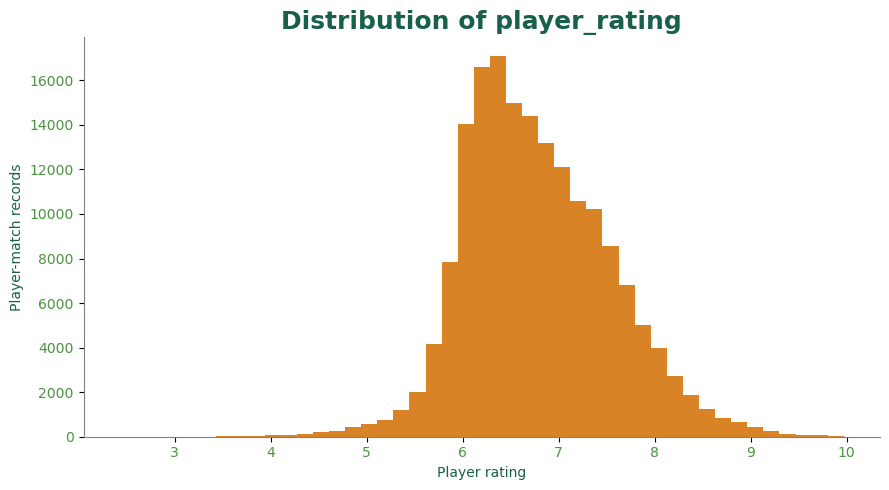

In [19]:
target_stats = df_clean[TARGET].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
display(target_stats.to_frame("player_rating"))

plt.figure(figsize=(9, 5))
plt.hist(df_clean[TARGET], bins=45,color="#D98327")
plt.xlabel("Player rating",color="#186049")
plt.ylabel("Player-match records",color="#186049")
plt.title("Distribution of player_rating",color="#186049",fontsize=18,weight="bold")
plt.xticks(color="#4A943E")
plt.yticks(color="#4A943E")
ax=plt.gca()
ax.spines[["top","right"]].set_visible(False)
ax.spines[["bottom","left"]].set_color("gray")
plt.tight_layout()
plt.show()

The histogram shows whether ratings are concentrated around a central range, whether the distribution is symmetric or skewed, and whether very high or low ratings are rare

### Do goalkeepers and outfield players receive different player ratings?

,count,mean,median,std,min,max
is_goalkeeper,,,,,,
Outfield,160445,6.771962,6.68,0.732147,2.80,9.97
Goalkeeper,13142,6.846266,6.87,1.016419,2.43,9.68


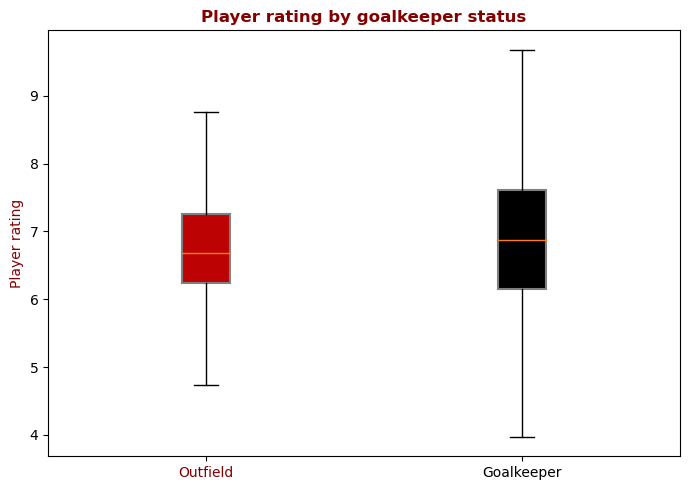

In [21]:
rating_by_role = df_clean.groupby("is_goalkeeper")[TARGET].agg(["count", "mean", "median", "std", "min", "max"])
rating_by_role.index = rating_by_role.index.map({0: "Outfield", 1: "Goalkeeper"})
display(rating_by_role)

plt.figure(figsize=(7, 5))
bp=plt.boxplot(
    [
        df_clean.loc[df_clean["is_goalkeeper"].eq(0), TARGET],
        df_clean.loc[df_clean["is_goalkeeper"].eq(1), TARGET]
    ],
    labels=["Outfield", "Goalkeeper"],
    showfliers=False,patch_artist=True
)
box_color=["#BC0202","#000000"]
for box , color in zip(bp["boxes"],box_color):
    box.set_facecolor(color)
    box.set_edgecolor("gray")
    box.set_linewidth(1.5)

plt.ylabel("Player rating",color="#830000")
plt.title("Player rating by goalkeeper status",color="#830000",weight="bold")
ax = plt.gca()

ax.get_xticklabels()[0].set_color("#830000")
ax.get_xticklabels()[1].set_color("#000000")
plt.tight_layout()
plt.show()

The standard deviation is higher for goalkeepers (**1.02**) than for outfield players (**0.73**), indicating that goalkeeper ratings are more dispersed and vary more from match to match.
The boxplot supports these findings. The median rating for goalkeepers is slightly higher, and the goalkeeper box and whiskers are wider, showing greater variability in their match ratings. Outfield-player ratings are more concentrated around the central range.

Overall, the distributions overlap substantially, so goalkeeper status alone does not separate player ratings strongly. However, goalkeepers appear to have slightly higher typical ratings and greater variability than outfield players.

Goalkeepers have a slightly higher typical rating than outfield players, but the difference is small.Their ratings are also more variable, as shown by both the higher standard deviation and the wider boxplot. The two distributions still overlap considerably, so goalkeeper status by itself does not strongly determine player rating


### How large is the difference in player ratings between wins, draws, and losses, and how much do the distributions overlap?

,count,mean,median,std
team_result,,,,
win,63637,7.178516,7.16,0.736411
draw,42957,6.804080,6.74,0.640290
NaN,253,6.664506,6.56,0.832058
loss,66740,6.378677,6.34,0.629771


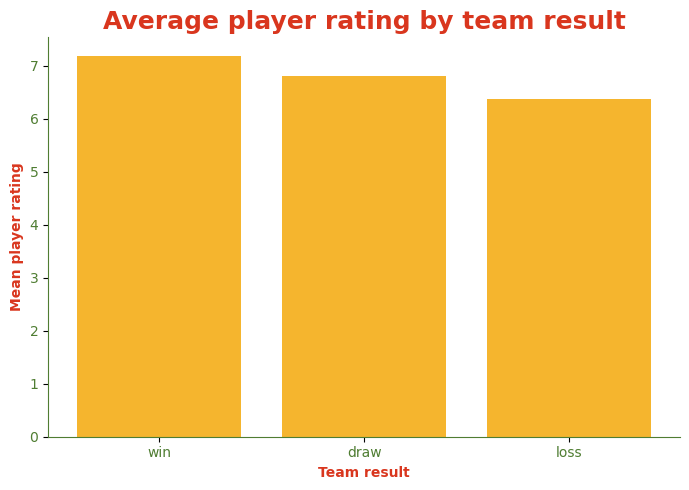

In [25]:
result_summary = (
    df_clean.groupby("team_result", dropna=False)[TARGET]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean", ascending=False)
)
display(result_summary)

valid_results = [r for r in ["win", "draw", "loss"] if r in df_clean["team_result"].dropna().unique()]
plt.figure(figsize=(7, 5))
plt.bar(valid_results, [df_clean.loc[df_clean["team_result"].eq(r), TARGET].mean() for r in valid_results],color="#F5B52E")
plt.ylabel("Mean player rating",color="#D9361E",weight="bold")
plt.xlabel("Team result",color="#D9361E",weight="bold")
plt.title("Average player rating by team result",color="#D9361E",weight="bold",fontsize=18)
plt.xticks(color="#4F7D32")
plt.yticks(color="#4F7D32")
ax=plt.gca()
ax.spines[["top","right"]].set_visible(False)
ax.spines[["bottom","left"]].set_color("#4F7D32")
plt.tight_layout()
plt.show()

The `mean` rating for players on winning teams is **7.17**, compared with **6.80** for draws and **6.37** for losses. Although this direction is expected in football, the analysis quantifies how strongly match outcome is reflected in the rating system.

### How does rating behave across different amounts of playing time?

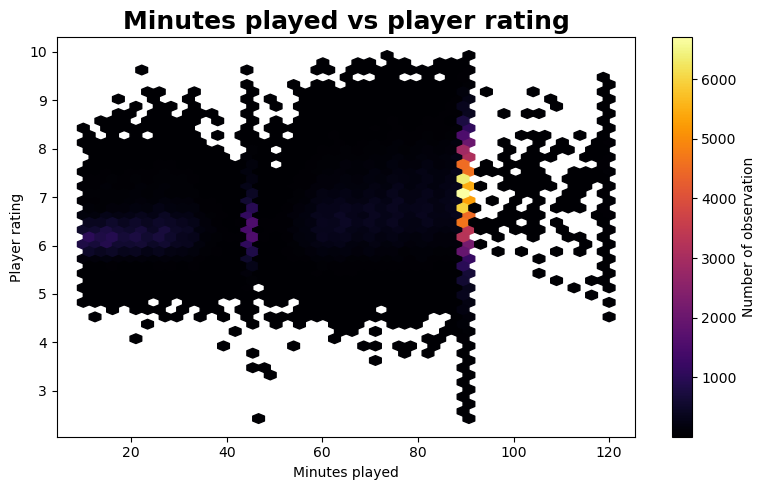

In [40]:
plt.figure(figsize=(8, 5))
valid_minutes = df_clean["minutes_played"].notna()
plt.hexbin(
    df_clean.loc[valid_minutes, "minutes_played"],
    df_clean.loc[valid_minutes, TARGET],
    gridsize=45,
    mincnt=1,cmap="inferno"
)
plt.colorbar(label="Number of observation")
plt.xlabel("Minutes played")
plt.ylabel("Player rating")
plt.title("Minutes played vs player rating",weight="bold",fontsize=18)
plt.tight_layout()
plt.show()

A hexbin plot was used instead of a standard scatter plot because the dataset contains over 170,000 player-match records.

The highest concentration occurs around **90 minutes**, which is expected because many players complete a full match. Ratings in this region are distributed across a broad range, although many observations cluster around the mid-6 to low-7 rating range.

There is no clear linear pattern showing that more minutes automatically leads to a higher rating. Players with both short and long appearances can receive low or high ratings.

A smaller number of observations appear above 90 minutes, up to 120 minutes, which likely correspond to matches that went into extra time.

Overall, `minutes_played` appears to describe match exposure rather than directly determine player rating.

### How does the average player rating change with the number of goals scored?

,goals,count,mean,median
0,0.0,146925,6.666515,6.600
1,1.0,12348,7.812425,7.810
2,2.0,1062,8.939812,8.950
3,3.0,105,9.614381,9.660
4,4.0,14,9.876428,9.875
5,5.0,2,9.955000,9.955
6,6.0,2,9.965000,9.965
7,8.0,1,9.970000,9.970


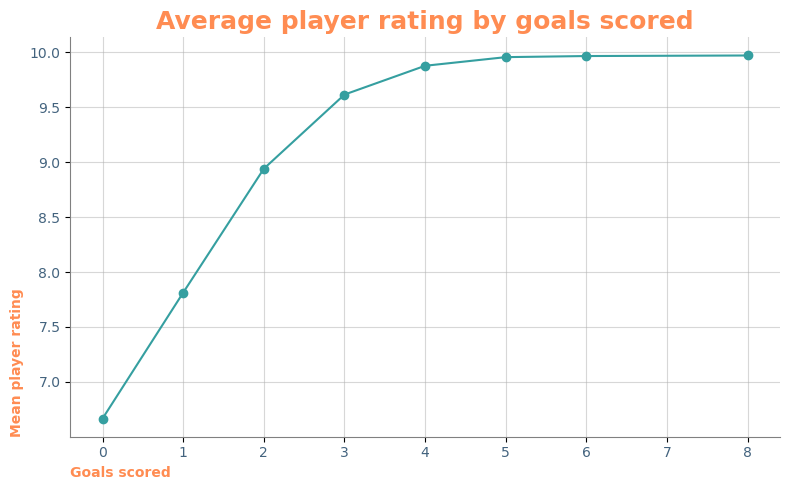

In [48]:
goal_summary = (
    df_clean.loc[df_clean["goals"].notna()]
    .groupby("goals")[TARGET]
    .agg(["count", "mean", "median"])
    .reset_index()
)

display(goal_summary)

plt.figure(figsize=(8, 5))
plt.plot(
    goal_summary["goals"],
    goal_summary["mean"],
    marker="o",color="#359FA0"
)
plt.xlabel("Goals scored",loc="left",color="#FF8C52",weight="bold")
plt.ylabel("Mean player rating",loc="bottom",color="#FF8C52",weight="bold")
plt.title("Average player rating by goals scored",weight="bold",fontsize=18,color="#FF8C52")
plt.xticks(color="#43637E")
plt.yticks(color="#43637E")
plt.grid(alpha=0.5)
plt.tight_layout()
ax=plt.gca()
ax.spines[["top","right"]].set_visible(False)
ax.spines[["bottom","left"]].set_color("gray")
plt.show()

Among records with observed goal values, the average player rating increases strongly
as the number of goals scored increases. However, the number of observations becomes
very small for extreme goal totals, so ratings for players scoring four or more goals
should be interpreted cautiously.

The strong conclusion is reliable for 0, 1, 2 and probably 3 goals; the extreme-goal section should be described as rare observations, not a stable general pattern

### When one numeric feature changes, does player_rating tend to move with it, and how strongly?

,correlation_with_player_rating
goals,0.493008
goal_difference,0.470892
ground_duels_won,0.413076
touches,0.408710
shots_on_target,0.408466
chances_created,0.400336
xg_plus_xa,0.394779
minutes_played,0.382578
duels_won,0.382287
opponent_goals,-0.354529


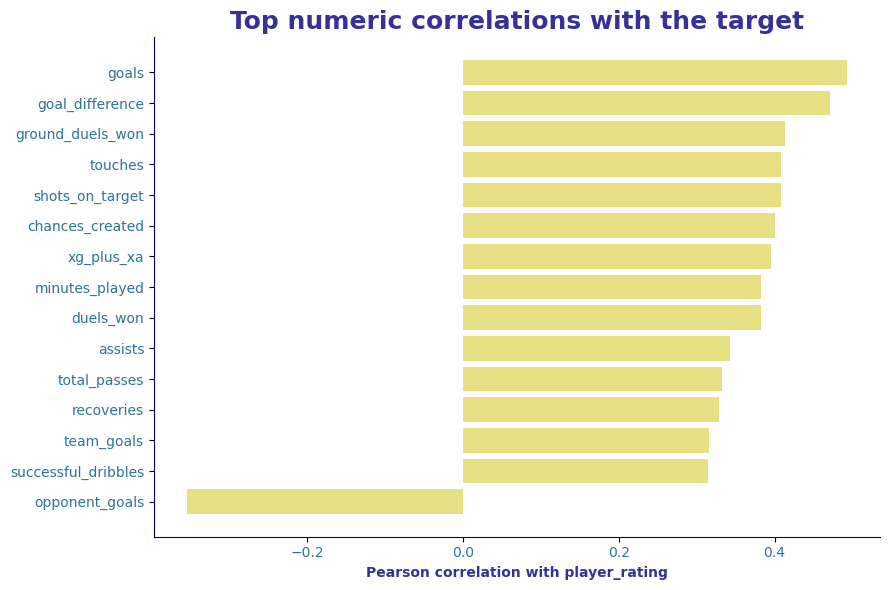

In [53]:

numeric_corr = (
    df_clean.select_dtypes(include=np.number)
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .dropna()
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
display(numeric_corr.head(20).to_frame("correlation_with_player_rating"))

top_corr = numeric_corr.head(15).sort_values()
plt.figure(figsize=(9, 6))
plt.barh(top_corr.index, top_corr.values,color="#E8E085")
plt.xlabel("Pearson correlation with player_rating",color="#363199",weight="bold")
plt.title("Top numeric correlations with the target",color="#363199",weight="bold",fontsize=18)
plt.xticks(color="#2D7495")
plt.yticks(color="#2D7495")
ax=plt.gca()
ax.spines[["top","right"]].set_visible(False)
ax.spines[["bottom","left"]].set_color("#030164")
plt.tight_layout()
plt.show()

A positive correlation indicates that larger feature values tend to be
associated with higher player ratings, while a negative correlation indicates
that larger values tend to be associated with lower ratings.

Correlation values closer to +1 or -1 represent stronger linear relationships,
whereas values closer to 0 indicate a weak linear relationship.

These correlations are descriptive and should not be interpreted as causal
effects. In addition, a low Pearson correlation does not necessarily mean that
a feature is unimportant for the machine-learning model, because nonlinear
relationships may still exist.

### Which passing-related features are most strongly associated with player rating?

,attacking_feature,Pearson,Spearman,Absolute_Spearman
1,accurate_passes,0.302268,0.391684,0.391684
0,passes_final_third,0.232437,0.279358,0.279358
2,accurate_crosses,0.227060,0.207948,0.207948
3,accurate_long_balls,0.128623,0.174224,0.174224


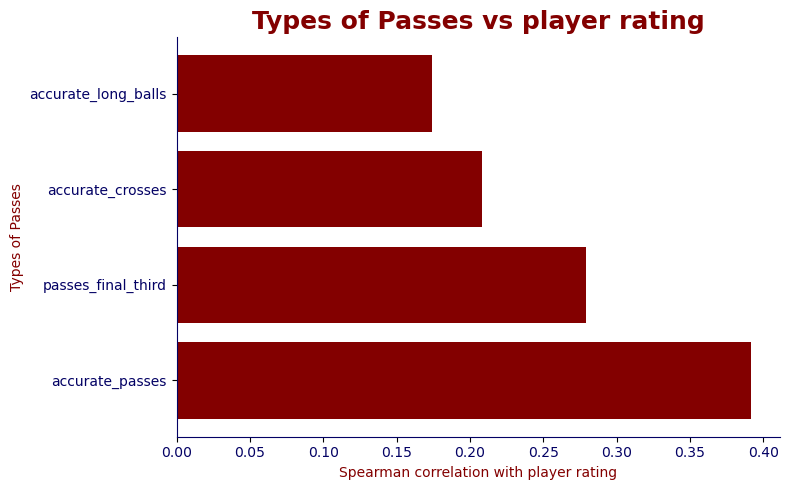

In [83]:
selected_attacking = [
    "passes_final_third",
    "accurate_passes",
    "accurate_crosses",
    "accurate_long_balls"
]

comparison = pd.DataFrame({
    "attacking_feature":selected_attacking,
    "Pearson": [df_clean[[col, TARGET]].corr(method="pearson").loc[col, TARGET] for col in selected_attacking],
    "Spearman": [df_clean[[col, TARGET]].corr(method="spearman").loc[col, TARGET] for col in selected_attacking]
    })

comparison["Absolute_Spearman"] = comparison["Spearman"].abs()
comparison = comparison.sort_values("Absolute_Spearman",ascending=False)
display(comparison)


plt.figure(figsize=(8, 5))

plt.barh(comparison["attacking_feature"],comparison["Spearman"],color="#830000")
plt.xlabel("Spearman correlation with player rating",color="#830000")
plt.ylabel("Types of Passes",color="#830000")
plt.title("Types of Passes vs player rating",color="#830000",weight="bold",fontsize=18)
plt.xticks(color="#030164")
plt.yticks(color="#030164")
ax=plt.gca()
ax.spines[["top","right"]].set_visible(False)
ax.spines[["bottom","left"]].set_color("#030164")
plt.tight_layout()
plt.show()

Both Pearson and Spearman correlations were calculated. Spearman correlation
is emphasized because many football event variables are skewed, contain many
zero values, and may have monotonic but not perfectly linear relationships
with player rating.

`accurate_crosses` has a weaker positive association, while
`accurate_long_balls` has the weakest relationship with player rating.

All four relationships are positive, meaning that higher values generally tend
to occur with higher player ratings. However, these correlations describe
association only and should not be interpreted as causal effects.

### Which defensive actions are most strongly associated with player rating?

,defensive_feature,Pearson,Spearman
0,ground_duels_won,0.413076,0.437279
1,recoveries,0.328277,0.391541
2,tackles_won,0.295214,0.315412
3,interceptions,0.217296,0.242925
4,aerial_duels_won,0.186498,0.207527


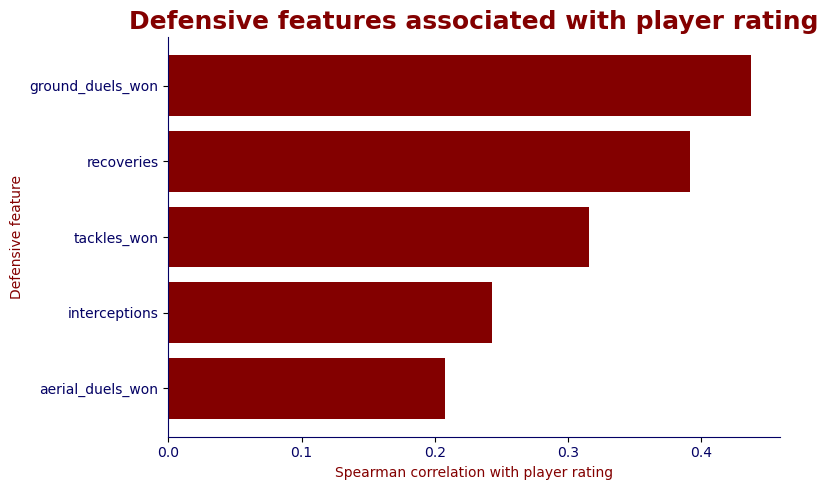

In [89]:
selected_defensive = [
    "ground_duels_won",
    "aerial_duels_won",
    "recoveries",
    "tackles_won",
    "interceptions"
]

defensive_comparison = pd.DataFrame({
    "defensive_feature": selected_defensive,
    "Pearson": [df_clean[[col, TARGET]].corr(method="pearson").loc[col, TARGET]for col in selected_defensive],
    "Spearman": [df_clean[[col, TARGET]].corr(method="spearman").loc[col, TARGET]for col in selected_defensive]
})
defensive_comparison = defensive_comparison.sort_values("Spearman",ascending=False).reset_index(drop=True)
display(defensive_comparison)

plt.figure(figsize=(8, 5))

plt.barh(
    defensive_comparison["defensive_feature"],
    defensive_comparison["Spearman"],color="#830000"
)

plt.xlabel("Spearman correlation with player rating",color="#830000")
plt.ylabel("Defensive feature",color="#830000")
plt.title("Defensive features associated with player rating",color="#830000",weight="bold",fontsize=18)
plt.xticks(color="#030164")
plt.yticks(color="#030164")
ax=plt.gca()
ax.spines[["top","right"]].set_visible(False)
ax.spines[["bottom","left"]].set_color("#030164")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

ground_duels_won has the strongest positive association with player rating

### Does the distribution or average level of player ratings differ across competitions?

In [65]:
league_summary = (
    df_clean.groupby("league_name")[TARGET]
    .agg(["count", "mean", "median"])
)

league_summary = (
    league_summary[league_summary["count"] >= 1000]
    .sort_values("mean", ascending=False)
)

display(league_summary.head(20))

,count,mean,median
league_name,,,
Baller League,1818,6.907921,6.780
Saudi Pro League,2654,6.874356,6.805
Allsvenskan,2267,6.851923,6.760
Veikkausliiga,1389,6.848611,6.760
Eliteserien,1683,6.839655,6.730
Ligue 1,2534,6.834716,6.730
Besta deildin,1444,6.830305,6.730
Eredivisie,2521,6.822519,6.740
Super Lig,2800,6.821054,6.740


### Is home-team status associated with higher player ratings?

In [ ]:
home_away_summary = (df_clean.groupby("is_home_team")[TARGET].agg(["count", "mean", "median", "std"]))
home_away_summary.index = home_away_summary.index.map({0: "Away",1: "Home"})
display(home_away_summary)

,count,mean,median,std
is_home_team,,,,
Away,87697,6.708486,6.61,0.748938
Home,85890,6.848143,6.77,0.760017


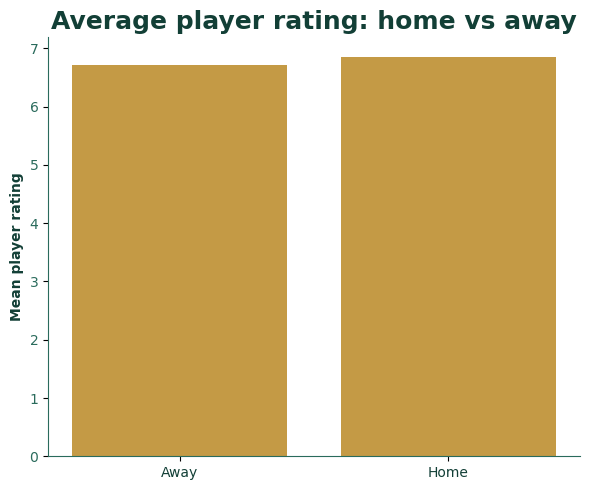

In [79]:
plt.figure(figsize=(6, 5))

plt.bar(home_away_summary.index,home_away_summary["mean"],color="#C49A45")
plt.ylabel("Mean player rating",color="#123F36",weight="bold")
plt.title("Average player rating: home vs away",weight="bold",color="#123F36",fontsize=18)
plt.xticks(color="#2A6B5C")
plt.yticks(color="#2A6B5C")
ax=plt.gca()
labels = ax.get_xticklabels()
labels[0].set_color("#123F36")
labels[1].set_color("#123F36")
ax.spines[["top","right"]].set_visible(False)
ax.spines[["bottom","left"]].set_color("#2A6B5C")
plt.tight_layout()
plt.show()

Players on home teams have an average rating of `6.84`, while players on away teams have an average rating of `6.70`. This suggests that home-team status is associated with slightly higher player ratings in this dataset.

### Which foul-related statistic is more strongly associated with player rating: fouls committed or being fouled?

,feature,Pearson,Spearman
0,fouls_committed,0.020994,0.032748
1,was_fouled,0.147732,0.147615


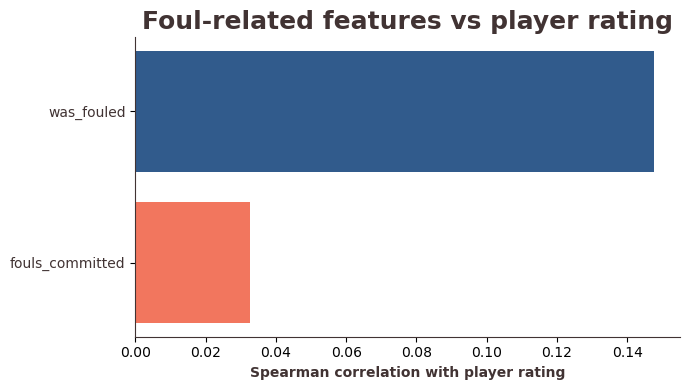

In [85]:
foul_features = ["fouls_committed","was_fouled"]

foul_corr = pd.DataFrame({
    "feature": foul_features,
    "Pearson": [df_clean[[col, TARGET]].corr(method="pearson").loc[col, TARGET]for col in foul_features],
    "Spearman": [df_clean[[col, TARGET]].corr(method="spearman").loc[col, TARGET]for col in foul_features]})

display(foul_corr)

plt.figure(figsize=(7, 4))

plt.barh(foul_corr["feature"],foul_corr["Spearman"],color=["#F2765E", "#315B8C"])

plt.xlabel("Spearman correlation with player rating",color="#413333",weight="bold")
plt.title("Foul-related features vs player rating",color="#413333",weight="bold",fontsize=18)
ax=plt.gca()
labels = ax.get_yticklabels()
labels[0].set_color("#413333")
labels[1].set_color("#413333")
ax.spines[["top","right"]].set_visible(False)
ax.spines[["bottom","left"]].set_color("#413333")

plt.tight_layout()
plt.show()

`was_fouled` shows a stronger positive association with player rating than `fouls_committed`. However, the correlation is still weak, so being fouled is only modestly related to higher ratings, while committing fouls has almost no relationship with rating.

# 6. Column review for modeling

The clean delivery dataset and the model dataset have different purposes.

- The **clean delivery dataset** keeps traceability columns such as player/team names and IDs (except constant/redundant columns already justified above).
- The **model dataset** excludes high-cardinality identifiers/names to avoid memorizing individual players, teams or matches.
- Raw `home_score` and `away_score` are excluded because team-perspective `team_goals`, `opponent_goals` and `goal_difference` already carry match-score context.
- Raw `match_date` is converted to simple date features.
- The 253 rows with inconsistent team-to-match linkage are excluded from modeling only; they remain in the clean delivery dataset.

In [47]:
model_data = df_clean.loc[df_clean["team_link_valid"].eq(1)].copy()

# Date features
model_data["match_month"] = model_data["match_date"].dt.month.astype("int8")
model_data["match_dayofweek"] = model_data["match_date"].dt.dayofweek.astype("int8")
model_data["days_since_start"] = (
    model_data["match_date"] - model_data["match_date"].min()
).dt.days.astype("int16")

DROP_FROM_MODEL = [
    TARGET,
    "match_id",
    "league_id",
    "home_team_id", "home_team_name",
    "away_team_id", "away_team_name",
    "player_id", "player_name",
    "team_id", "team_name",
    "match_date",
    "home_score", "away_score",
    "team_link_valid"
]

FEATURES = [c for c in model_data.columns if c not in DROP_FROM_MODEL]
CATEGORICAL_FEATURES = [c for c in FEATURES if model_data[c].dtype == "object"]

feature_decisions = pd.DataFrame({
    "column": df_clean.columns,
    "model_action": [
        "Target" if c == TARGET
        else "Exclude from model" if c in DROP_FROM_MODEL
        else "Keep"
        for c in df_clean.columns
    ]
})

display(feature_decisions)
print("Rows available for modeling:", len(model_data))
print("Rows excluded for inconsistent team linkage:", len(df_clean) - len(model_data))
print("Model feature count:", len(FEATURES))
print("Categorical features:", CATEGORICAL_FEATURES)

,column,model_action
0,match_id,Exclude from model
1,match_date,Exclude from model
2,league_id,Exclude from model
3,league_name,Keep
4,country_code,Keep
5,home_team_id,Exclude from model
6,home_team_name,Exclude from model
7,away_team_id,Exclude from model
8,away_team_name,Exclude from model
9,home_score,Exclude from model


Rows available for modeling: 173334
Rows excluded for inconsistent team linkage: 253
Model feature count: 50
Categorical features: ['league_name', 'country_code', 'team_result']


# 7. Chronological train / validation / test split

The project period is chronological, so a time-aware split is used instead of the main random split:
- first ~70% of unique dates → train,
- next ~15% → validation,
- final ~15% → test.

This provides a more realistic test of performance on later matches.

In [48]:
unique_dates = np.array(sorted(model_data["match_date"].dt.normalize().dropna().unique()))
cut_70 = pd.Timestamp(unique_dates[int(len(unique_dates) * 0.70)])
cut_85 = pd.Timestamp(unique_dates[int(len(unique_dates) * 0.85)])

train = model_data.loc[model_data["match_date"] < cut_70].copy()
valid = model_data.loc[
    (model_data["match_date"] >= cut_70) & (model_data["match_date"] < cut_85)
].copy()
test = model_data.loc[model_data["match_date"] >= cut_85].copy()

split_summary = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "rows": [len(train), len(valid), len(test)],
    "min_date": [train["match_date"].min(), valid["match_date"].min(), test["match_date"].min()],
    "max_date": [train["match_date"].max(), valid["match_date"].max(), test["match_date"].max()],
    "target_mean": [train[TARGET].mean(), valid[TARGET].mean(), test[TARGET].mean()]
})
display(split_summary)

assert train["match_date"].max() < valid["match_date"].min()
assert valid["match_date"].max() < test["match_date"].min()

,split,rows,min_date,max_date,target_mean
0,Train,128292,2025-01-31,2025-05-05,6.764683
1,Validation,30998,2025-05-06,2025-05-20,6.817930
2,Test,14044,2025-05-21,2025-06-08,6.808466


# 8. Baseline model

The baseline predicts the training-set mean rating for every test observation. CatBoost should outperform this simple reference.


In [49]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

baseline_pred = np.full(len(test), train[TARGET].mean())
baseline_metrics = regression_metrics(test[TARGET], baseline_pred)

display(pd.DataFrame(
    [{"model": "Mean baseline", **baseline_metrics}]
).set_index("model"))

,MAE,RMSE,R2
model,,,
Mean baseline,0.627438,0.797592,-0.003023


# 9. CatBoost regression

Why CatBoost is appropriate here:
- strong performance on tabular data;
- nonlinear interactions between football actions;
- native handling of categorical variables;
- native handling of numeric NaNs;
- relatively robust to extreme values;
- built-in feature importance and SHAP support.

No standardization is required for tree-based CatBoost.

In [50]:
X_train = train[FEATURES].copy()
y_train = train[TARGET].copy()

X_valid = valid[FEATURES].copy()
y_valid = valid[TARGET].copy()

X_test = test[FEATURES].copy()
y_test = test[TARGET].copy()

# CatBoost categorical columns cannot contain NaN strings.
for col in CATEGORICAL_FEATURES:
    X_train[col] = X_train[col].fillna("__MISSING__").astype(str)
    X_valid[col] = X_valid[col].fillna("__MISSING__").astype(str)
    X_test[col] = X_test[col].fillna("__MISSING__").astype(str)

model = CatBoostRegressor(
    iterations=800,
    depth=8,
    learning_rate=0.07,
    loss_function="RMSE",
    eval_metric="MAE",
    random_seed=RANDOM_SEED,
    l2_leaf_reg=5,
    random_strength=0.5,
    verbose=100,
    allow_writing_files=False,
    thread_count=-1
)

model.fit(
    X_train, y_train,
    cat_features=CATEGORICAL_FEATURES,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=80,
    use_best_model=True
)

print("Best iteration:", model.get_best_iteration())

0:	learn: 0.5657666	test: 0.6018516	best: 0.6018516 (0)	total: 279ms	remaining: 3m 43s
100:	learn: 0.1826023	test: 0.1981889	best: 0.1981889 (100)	total: 13.7s	remaining: 1m 34s
200:	learn: 0.1626008	test: 0.1790785	best: 0.1790785 (200)	total: 26.4s	remaining: 1m 18s
300:	learn: 0.1529416	test: 0.1709879	best: 0.1709879 (300)	total: 39.8s	remaining: 1m 5s
400:	learn: 0.1474437	test: 0.1670003	best: 0.1670003 (400)	total: 52.7s	remaining: 52.4s
500:	learn: 0.1436668	test: 0.1645404	best: 0.1645404 (500)	total: 1m 5s	remaining: 39.1s
600:	learn: 0.1401181	test: 0.1625487	best: 0.1625487 (600)	total: 1m 18s	remaining: 25.9s
700:	learn: 0.1374122	test: 0.1611940	best: 0.1611690 (699)	total: 1m 30s	remaining: 12.8s
799:	learn: 0.1350381	test: 0.1601508	best: 0.1601508 (799)	total: 1m 43s	remaining: 0us

bestTest = 0.1601507706
bestIteration = 799

Best iteration: 799


# 10. Model evaluation

Primary metric: **MAE** because it is directly interpretable in rating points.

Also report:
- **RMSE** — penalizes large errors more strongly;
- **R²** — proportion of target variance explained relative to a constant predictor.

In [ ]:
valid_pred = model.predict(X_valid)
test_pred = model.predict(X_test)

valid_metrics = regression_metrics(y_valid, valid_pred)
test_metrics = regression_metrics(y_test, test_pred)

metrics_table = pd.DataFrame([
    {"model": "Mean baseline (test)", **baseline_metrics},
    {"model": "CatBoost validation", **valid_metrics},
    {"model": "CatBoost test", **test_metrics}
]).set_index("model")

display(metrics_table)

improvement_mae = 100 * (
    baseline_metrics["MAE"] - test_metrics["MAE"]
) / baseline_metrics["MAE"]

print(f"MAE improvement over mean baseline: {improvement_mae:.1f}%")
print(
    f"Non-technical interpretation: on the held-out future period, "
    f"the model misses the player rating by about {test_metrics['MAE']:.3f} "
    f"rating points on average."
)

## 10.1 Subgroup evaluation

A good overall metric can hide weak performance for particular football roles or rating ranges.

In [ ]:
test_eval = test[
    ["player_name", "league_name", "is_goalkeeper", "minutes_played", TARGET]
].copy()
test_eval["prediction"] = test_pred
test_eval["residual"] = test_eval[TARGET] - test_eval["prediction"]
test_eval["abs_error"] = test_eval["residual"].abs()

def subgroup_metrics(frame, group_col):
    rows = []
    for group, sub in frame.groupby(group_col, dropna=False):
        if len(sub) < 2:
            continue
        rows.append({
            group_col: group,
            "n": len(sub),
            "MAE": mean_absolute_error(sub[TARGET], sub["prediction"]),
            "RMSE": np.sqrt(mean_squared_error(sub[TARGET], sub["prediction"])),
            "R2": r2_score(sub[TARGET], sub["prediction"])
        })
    return pd.DataFrame(rows)

test_eval["player_type"] = np.where(
    test_eval["is_goalkeeper"].eq(1), "Goalkeeper", "Outfield"
)
display(subgroup_metrics(test_eval, "player_type"))

test_eval["minutes_band"] = pd.cut(
    test_eval["minutes_played"],
    bins=[-np.inf, 30, 60, 89, np.inf],
    labels=["<=30", "31-60", "61-89", "90+"]
)
display(subgroup_metrics(test_eval, "minutes_band"))

test_eval["rating_band"] = pd.cut(
    test_eval[TARGET],
    bins=[-np.inf, 6, 7, 8, 9, np.inf],
    labels=["<6", "6-7", "7-8", "8-9", "9+"],
    right=False
)
display(subgroup_metrics(test_eval, "rating_band"))

# 11. Feature importance

Feature importance describes what the fitted model relies on most. It does not prove causal influence.

In [ ]:
importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": model.get_feature_importance()
}).sort_values("importance", ascending=False)

display(importance.head(25))

top_imp = importance.head(20).sort_values("importance")
plt.figure(figsize=(9, 7))
plt.barh(top_imp["feature"], top_imp["importance"])
plt.xlabel("CatBoost feature importance")
plt.title("Top 20 model features")
plt.tight_layout()
plt.show()

## 11.1 SHAP directionality on a sample

CatBoost SHAP values help answer not just *which* features matter, but whether a feature pushed an individual prediction higher or lower.

To keep the notebook practical, SHAP is computed on a reproducible sample of the test set.

In [ ]:
SHAP_SAMPLE_N = min(2000, len(X_test))
shap_sample = X_test.sample(SHAP_SAMPLE_N, random_state=RANDOM_SEED)
shap_pool = Pool(shap_sample, cat_features=CATEGORICAL_FEATURES)

shap_values = model.get_feature_importance(
    shap_pool,
    type="ShapValues"
)

# Last column is the expected value / baseline.
mean_abs_shap = np.abs(shap_values[:, :-1]).mean(axis=0)

shap_importance = pd.DataFrame({
    "feature": FEATURES,
    "mean_abs_shap": mean_abs_shap
}).sort_values("mean_abs_shap", ascending=False)

display(shap_importance.head(20))

# 12. Residual analysis

Residual = actual rating − predicted rating.

- positive residual: model under-predicted the player;
- negative residual: model over-predicted the player.

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(test_eval["residual"], bins=50)
plt.xlabel("Residual (actual - predicted)")
plt.ylabel("Player-match records")
plt.title("Residual distribution on the held-out test period")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
plt.hexbin(
    test_eval["prediction"],
    test_eval[TARGET],
    gridsize=45,
    mincnt=1
)
lims = [
    min(test_eval["prediction"].min(), test_eval[TARGET].min()),
    max(test_eval["prediction"].max(), test_eval[TARGET].max())
]
plt.plot(lims, lims, linestyle="--")
plt.xlabel("Predicted rating")
plt.ylabel("Actual rating")
plt.title("Actual vs predicted player rating")
plt.tight_layout()
plt.show()

In [ ]:
# Largest errors are inspected, not automatically deleted.
largest_errors = test_eval.sort_values("abs_error", ascending=False).head(30)
display(largest_errors)

print("Mean residual:", test_eval["residual"].mean())
print("Median absolute error:", test_eval["abs_error"].median())
print("95th percentile absolute error:", test_eval["abs_error"].quantile(0.95))

# 13. Football-oriented technical summary

Run the next cell after the model completes. It generates a concise summary from the actual measured results rather than hard-coding conclusions.

In [ ]:
top_features = importance.head(10)["feature"].tolist()

summary_text = f'''
TECHNICAL SUMMARY
-----------------
Rows analysed: {len(data):,}
Original columns: {df_raw.shape[1]}
Target: {TARGET}
Duplicate player-match rows: {int(df.duplicated(["match_id", "player_id"]).sum())}
Train period: {train["match_date"].min().date()} to {train["match_date"].max().date()}
Validation period: {valid["match_date"].min().date()} to {valid["match_date"].max().date()}
Test period: {test["match_date"].min().date()} to {test["match_date"].max().date()}

Mean-baseline test MAE: {baseline_metrics["MAE"]:.4f}
CatBoost test MAE: {test_metrics["MAE"]:.4f}
CatBoost test RMSE: {test_metrics["RMSE"]:.4f}
CatBoost test R²: {test_metrics["R2"]:.4f}

Top model features:
{", ".join(top_features)}

OUTLIER POLICY
--------------
No legitimate statistical extreme was removed merely for being unusual.
Only logical impossibilities would justify correction/removal.

MISSING-VALUE POLICY
--------------------
No universal median/zero rule was used.
Nulls were treated according to football meaning and provider/role patterns.
CatBoost retained genuine numeric NaNs where appropriate.
'''
print(summary_text)

# 14. Non-technical football summary

The cell below translates the measured test performance into language suitable for a coach, scout or sporting director.

In [ ]:
print(
    f"The model was tested only on later matches that were not used for training. "
    f"On those matches, its average error was {test_metrics['MAE']:.2f} rating points, "
    f"compared with {baseline_metrics['MAE']:.2f} for a simple average-rating prediction. "
    f"It explained about {test_metrics['R2']*100:.1f}% of the variation in ratings in the held-out period.\n\n"
    f"The most influential variables in this fitted model were: "
    f"{', '.join(top_features[:8])}. "
    f"These importances describe the model's rating reconstruction process; they do not prove that a statistic causes a rating change.\n\n"
    f"Missing values were not treated as one generic problem. "
    f"'No event', undefined percentages, goalkeeper-specific missingness and competition/provider gaps "
    f"were handled separately. Genuine extreme football performances were retained."
)

# 15. Limitations and next steps

1. **This is a rating-estimation model, not a pre-match forecast.** Same-match actions are included.
2. The dataset covers a relatively short window (January–June 2025); model stability should be re-tested on later seasons.
3. `player_rating` may itself be generated by a provider algorithm partly from the same event statistics. High predictive accuracy can therefore reflect successful reconstruction of that rating logic.
4. Competition/provider missingness can carry information. The notebook preserves this rather than pretending every null equals zero.
5. Position is represented mainly through `is_goalkeeper`; richer position labels (CB, FB, DM, AM, winger, striker) would improve subgroup analysis if available.
6. For deployment, the exact preprocessing and feature list used here must be applied identically to future data.

## Optional: save key analytical outputs

These files make the audit and modeling decisions easy to review outside the notebook.

In [ ]:
OUTPUT_DIR = Path("football_rating_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

audit.to_csv(OUTPUT_DIR / "all_63_columns_audit.csv", index=False)
missing_decisions.to_csv(OUTPUT_DIR / "missing_value_decisions.csv", index=False)
feature_decisions.to_csv(OUTPUT_DIR / "feature_selection_decisions.csv", index=False)
metrics_table.to_csv(OUTPUT_DIR / "model_metrics.csv")
importance.to_csv(OUTPUT_DIR / "catboost_feature_importance.csv", index=False)
test_eval.to_csv(OUTPUT_DIR / "test_predictions_and_residuals.csv", index=False)

print("Saved analytical outputs to:", OUTPUT_DIR.resolve())